# Resultados finales: predicción paralela de mapas de calor (LST) en Tlaxcala y Puebla

**Tercer avance.** Se entrena con 2016–2023 y se predicen los **12 mapas de 2024**, un año que el modelo nunca vio, y se compara contra tres referencias sencillas.

**Paralelismo (multiprocessing, sin joblib ni n_jobs):**
1. Construcción de la tabla pixel-mes con memoria compartida (paralelismo de datos).
2. Búsqueda de hiperparámetros de KNN, RF y SVR (paralelización exploratoria, reparto estático vs. dinámico).
3. Predicción de los mapas de 2024 por bloques de pixeles (paralelismo de datos).

In [1]:
import os
for v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[v] = "1"          # cada proceso usa un solo hilo: el paralelismo lo controlamos nosotros

import ast
import time
import multiprocessing as mp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import datos
import modelos
import paralelo as par

RUTA_LST = os.environ.get("RUTA_LST", "LST_mensual.tif")
RUTA_NDVI = os.environ.get("RUTA_NDVI", "NDVI_mensual.tif")
RUTA_ALT = os.environ.get("RUTA_ALT", "ALTITUD.tif")
ANIO_PRUEBA = 2024
N_MAX_ENTRENAMIENTO = int(os.environ.get("N_MAX", 40000))
REPETIR_BUSQUEDA = False   # True = volver a correr las 46 combinaciones (≈40 min con 8 núcleos)
NUCLEOS = mp.cpu_count()
LISTA_PROCESOS = list(range(1, min(NUCLEOS, 8) + 1))   # 1, 2, 3, ..., 8

os.makedirs("resultados", exist_ok=True)
os.makedirs("figuras", exist_ok=True)
COLORES = {"KNN": "#2a78d6", "KNN_todos": "#0b3d91", "RF": "#eb6834", "SVR": "#1baf7a",
           "Persistencia_t1": "#9a9a9a", "Persistencia_t12": "#6b6b6b", "Climatologia": "#3d3d3d"}
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
print("Núcleos:", NUCLEOS, "| Procesos a medir:", LISTA_PROCESOS)

Núcleos: 8 | Procesos a medir: [1, 2, 3, 4, 5, 6, 7, 8]


## 1. Lectura de los mapas mensuales

In [2]:
mapas = datos.leer_mapas(RUTA_LST, RUTA_NDVI, RUTA_ALT)
lst, ndvi, alt, lat, lon = mapas
FORMA = alt.shape
EXTENSION = [lon[0], lon[-1], lat[-1], lat[0]]

Mapas: 120 meses de 329 x 261 pixeles


## 2. Construcción de la tabla en paralelo: versión del 2º avance vs. versión final

En el 2º avance, 8 procesos tardaban **más** que 1: cada proceso recibía una copia de los mapas y regresaba su bloque de la tabla serializado, y unir los bloques costaba más que armarlos.

La versión final (`datos.construir_variables`) pone los mapas y la tabla de salida en **memoria compartida**:
- **Fase 1:** cada proceso cuenta los registros válidos de su bloque de filas.
- **Suma prefija:** el proceso principal calcula dónde escribe cada bloque.
- **Fase 2:** cada proceso escribe sus registros directamente en la tabla compartida.

Se verifica que las dos versiones producen exactamente la misma tabla.

In [3]:
tiempos_v1, tiempos_v2 = {}, {}
for p in LISTA_PROCESOS:
    df_v1, tiempos_v1[p] = datos.construir_variables_v1(mapas, procesos=p)
    df, tiempos_v2[p] = datos.construir_variables(mapas, procesos=p)
    print(f"{p:>2} procesos:  v1 {tiempos_v1[p]:6.2f} s   v2 {tiempos_v2[p]:6.2f} s   ({len(df):,} filas)")

# Las dos versiones deben dar la misma tabla
cols = list(df_v1.columns)
dif = max(float(np.abs(df_v1[c].to_numpy(float) - df[c].to_numpy(float)).max()) for c in cols)
print("Misma tabla:", df_v1.shape == df[cols].shape, "| diferencia máxima =", dif)
del df_v1

tabla_v1 = par.metricas_paralelas(tiempos_v1).assign(version="v1 (2º avance)")
tabla_v2 = par.metricas_paralelas(tiempos_v2).assign(version="v2 (memoria compartida)")
construccion = pd.concat([tabla_v1, tabla_v2], ignore_index=True)
construccion.to_csv("resultados/construccion_tabla_v1_vs_v2.csv", index=False)
construccion.round(3)

 1 procesos:  v1  12.57 s   v2   2.24 s   (4,429,724 filas)
 2 procesos:  v1  11.53 s   v2   4.04 s   (4,429,724 filas)
 3 procesos:  v1  11.50 s   v2   4.17 s   (4,429,724 filas)
 4 procesos:  v1  12.50 s   v2   4.35 s   (4,429,724 filas)
 5 procesos:  v1  13.11 s   v2   4.35 s   (4,429,724 filas)
 6 procesos:  v1  14.71 s   v2   4.68 s   (4,429,724 filas)
 7 procesos:  v1  16.03 s   v2   4.68 s   (4,429,724 filas)
 8 procesos:  v1  17.52 s   v2   5.02 s   (4,429,724 filas)
Misma tabla: True | diferencia máxima = 0.0


,procesos,tiempo_s,speedup,eficiencia,karp_flatt,version
0,1,12.573,1.000,1.000,NaN,v1 (2º avance)
1,2,11.534,1.090,0.545,0.835,v1 (2º avance)
2,3,11.497,1.094,0.365,0.872,v1 (2º avance)
3,4,12.497,1.006,0.252,0.992,v1 (2º avance)
4,5,13.114,0.959,0.192,1.054,v1 (2º avance)
5,6,14.710,0.855,0.142,1.204,v1 (2º avance)
6,7,16.032,0.784,0.112,1.321,v1 (2º avance)
7,8,17.517,0.718,0.090,1.449,v1 (2º avance)
8,1,2.240,1.000,1.000,NaN,v2 (memoria compartida)
9,2,4.042,0.554,0.277,2.610,v2 (memoria compartida)


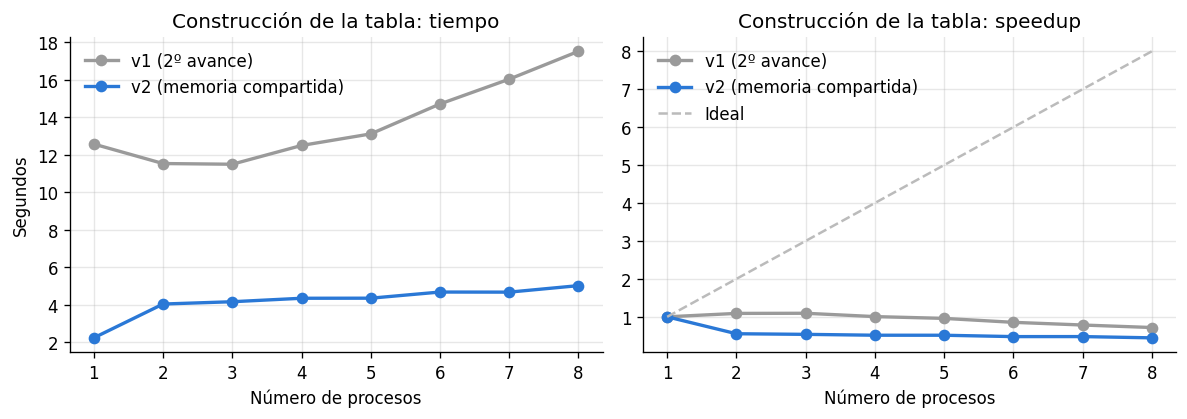

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for t, color in ((tabla_v1, "#9a9a9a"), (tabla_v2, "#2a78d6")):
    axes[0].plot(t["procesos"], t["tiempo_s"], marker="o", lw=2, color=color, label=t["version"][0])
    axes[1].plot(t["procesos"], t["speedup"], marker="o", lw=2, color=color, label=t["version"][0])
axes[1].plot(LISTA_PROCESOS, LISTA_PROCESOS, ls="--", color="#bbbbbb", label="Ideal")
axes[0].set_title("Construcción de la tabla: tiempo"); axes[0].set_ylabel("Segundos")
axes[1].set_title("Construcción de la tabla: speedup"); axes[1].legend(frameon=False)
for ax in axes:
    ax.set_xlabel("Número de procesos"); ax.set_xticks(LISTA_PROCESOS)
axes[0].legend(frameon=False)
fig.tight_layout(); fig.savefig("figuras/construccion_tabla_v1_vs_v2.png", dpi=200); plt.show()

In [5]:
resumen_datos = pd.DataFrame({"dato": ["Filas (pixel-mes)", "Pixeles con datos", "Meses", "Años"],
    "valor": [len(df), df.groupby(["fila", "col"]).ngroups, df[["anio", "mes"]].drop_duplicates().shape[0],
              f"{df['anio'].min()}–{df['anio'].max()}"]})
resumen_datos.to_csv("resultados/resumen_datos.csv", index=False)
resumen_datos

,dato,valor
0,Filas (pixel-mes),4429724
1,Pixeles con datos,41050
2,Meses,108
3,Años,2016–2024


## 3. Partición y búsqueda de hiperparámetros

- **Prueba:** los 12 mapas de 2024.
- **Entrenamiento y validación:** 2016–2023 (80 / 20). La búsqueda de 46 combinaciones usa una muestra de `N_MAX_ENTRENAMIENTO` registros (con 3 millones, un solo SVR tardaría días).
- **KNN con todos los datos:** con la mejor combinación de KNN se entrena además con **todo** el entrenamiento (≈3.1 millones de registros).

La búsqueda paralela (46 combinaciones) ya se corrió y sus tiempos están en `resultados/desempeno_paralelo.csv` y `resultados/estatico_vs_dinamico.csv`. Con `REPETIR_BUSQUEDA = True` se vuelve a correr.

In [6]:
ent, val, prueba = datos.particionar(df, anio_prueba=ANIO_PRUEBA, n_max_entrenamiento=N_MAX_ENTRENAMIENTO)
X_ent, y_ent = ent[datos.COLUMNAS_X].to_numpy(), ent[datos.COLUMNA_Y].to_numpy()
X_val, y_val = val[datos.COLUMNAS_X].to_numpy(), val[datos.COLUMNA_Y].to_numpy()
X_pru, y_pru = prueba[datos.COLUMNAS_X].to_numpy(), prueba[datos.COLUMNA_Y].to_numpy()

# Todos los registros de entrenamiento 2016-2023 (la muestra de arriba es un subconjunto)
ent_todo, _, _ = datos.particionar(df, anio_prueba=ANIO_PRUEBA, n_max_entrenamiento=None)
X_todo, y_todo = ent_todo[datos.COLUMNAS_X].to_numpy(), ent_todo[datos.COLUMNA_Y].to_numpy()
del ent_todo

if REPETIR_BUSQUEDA:
    tareas = modelos.lista_de_tareas()
    tiempos, resultados_por_p = {}, {}
    for p in LISTA_PROCESOS:
        res, tiempos[p] = par.busqueda(tareas, (X_ent, y_ent, X_val, y_val), procesos=p, reparto="dinamico")
        resultados_por_p[p] = pd.DataFrame(res)
        print(f"{p:>2} procesos: {tiempos[p]:8.2f} s")
    resultados_por_p[1].sort_values("RMSE").to_csv("resultados/busqueda_hiperparametros.csv", index=False)
    par.metricas_paralelas(tiempos).to_csv("resultados/desempeno_paralelo.csv", index=False)

busqueda = pd.read_csv("resultados/busqueda_hiperparametros.csv")
mejores = busqueda.sort_values("RMSE").groupby("modelo").head(1).set_index("modelo")
display(pd.read_csv("resultados/desempeno_paralelo.csv").round(3))
display(pd.read_csv("resultados/estatico_vs_dinamico.csv").round(3))
mejores[["params", "RMSE", "MAE", "R2"]]

Entrenamiento: 40,000 | Validación: 50,000 | Prueba (2024): 491,336
Entrenamiento: 3,150,711 | Validación: 50,000 | Prueba (2024): 491,336


,procesos,tiempo_s,speedup,eficiencia,karp_flatt
0,1,978.708,1.000,1.000,NaN
1,2,582.625,1.680,0.840,0.191
2,4,292.950,3.341,0.835,0.066
3,8,225.631,4.338,0.542,0.121


,reparto,procesos,tiempo_s,speedup
0,Estático (nivelar),8,327.844,2.985
1,Dinámico (imap_unordered),8,225.631,4.338


,params,RMSE,MAE,R2
modelo,,,,
KNN,"{'n_neighbors': 10, 'weights': 'distance', 'p'...",1.744445,1.300915,0.915171
RF,"{'n_estimators': 200, 'max_depth': None, 'min_...",1.802885,1.353838,0.909392
SVR,"{'C': 100, 'epsilon': 0.5, 'gamma': 0.1}",1.879888,1.399141,0.901487


## 4. Evaluación temporal de 2024 contra referencias

Cada modelo se entrena con su mejor combinación y predice los 12 mapas de 2024; KNN se entrena también con todos los datos (`KNN_todos`). Las referencias son:
- **Persistencia t−1:** el mes será igual al mes anterior.
- **Persistencia t−12:** el mes será igual al mismo mes del año anterior.
- **Climatología:** el promedio de ese mes en ese pixel durante 2016–2023.

In [7]:
import evaluacion as ev

entrenados, tiempo_entrenamiento = {}, {}
for nombre, fila in mejores.iterrows():
    m = modelos.crear_modelo(nombre, ast.literal_eval(fila["params"]))
    t0 = time.perf_counter(); m.fit(X_ent, y_ent); tiempo_entrenamiento[nombre] = time.perf_counter() - t0
    entrenados[nombre] = m
    print(f"{nombre}: entrenado en {tiempo_entrenamiento[nombre]:.1f} s")

prueba = ev.agregar_referencias(prueba, ev.climatologia(df, ANIO_PRUEBA))
for nombre, m in entrenados.items():
    procesos = NUCLEOS if nombre != "RF" else 1     # RF predice rápido; enviar sus 200 árboles a cada proceso no conviene
    prueba[f"pred_{nombre}"], t = par.predecir_paralelo(m, X_pru, procesos=procesos)
    print(f"{nombre}: {len(X_pru):,} pixeles predichos en {t:.1f} s con {procesos} procesos")

# KNN con TODOS los datos de entrenamiento (≈3.1 M registros), mismos hiperparámetros
from sklearn.preprocessing import StandardScaler
params_knn = ast.literal_eval(mejores.loc["KNN", "params"])
escala = StandardScaler().fit(X_todo)
X_todo_s, X_pru_s = escala.transform(X_todo), escala.transform(X_pru)
prueba["pred_KNN_todos"], t = par.predecir_knn_paralelo(X_todo_s, y_todo, X_pru_s, params_knn, procesos=NUCLEOS)
print(f"KNN_todos: {len(X_todo):,} registros de entrenamiento, {len(X_pru):,} pixeles predichos en {t:.1f} s con {NUCLEOS} procesos")

MODELOS = list(entrenados) + ["KNN_todos"]
METODOS = MODELOS + ["Persistencia_t1", "Persistencia_t12", "Climatologia"]
metricas_2024 = ev.tabla_metricas(prueba, METODOS)
metricas_2024.to_csv("resultados/metricas_2024.csv", index=False)
metricas_2024.round(3)

KNN: entrenado en 0.1 s
RF: entrenado en 52.7 s
SVR: entrenado en 570.5 s
KNN: 491,336 pixeles predichos en 57.2 s con 8 procesos
RF: 491,336 pixeles predichos en 13.1 s con 1 procesos
SVR: 491,336 pixeles predichos en 313.3 s con 8 procesos
KNN_todos: 3,150,711 registros de entrenamiento, 491,336 pixeles predichos en 163.3 s con 8 procesos


,metodo,RMSE,MAE,R2
0,RF,2.511,1.899,0.860
1,SVR,2.560,1.980,0.855
2,KNN,2.639,2.033,0.845
3,KNN_todos,2.768,2.093,0.830
4,Climatologia,2.887,2.297,0.815
5,Persistencia_t12,3.417,2.589,0.741
6,Persistencia_t1,3.929,2.990,0.658


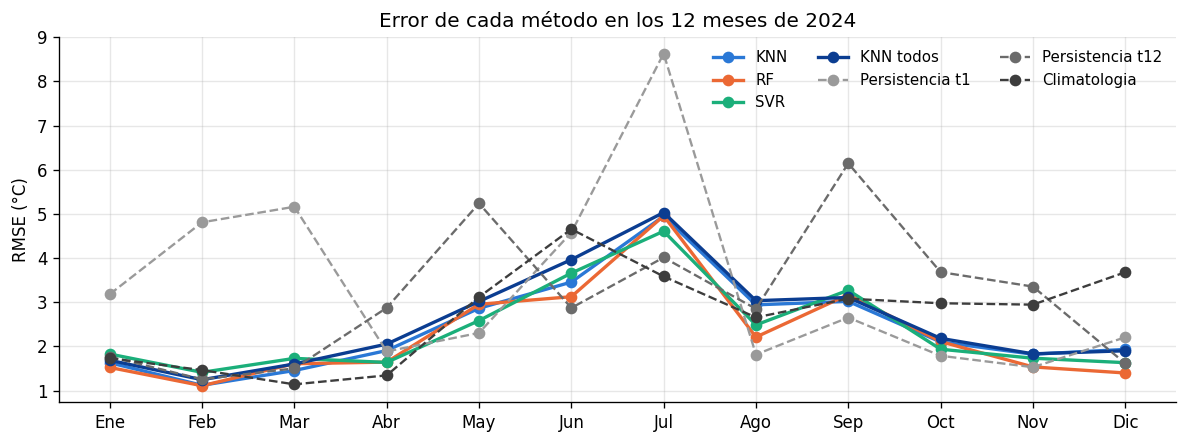

,mes,KNN,RF,SVR,KNN_todos,Persistencia_t1,Persistencia_t12,Climatologia
0,Ene,1.63,1.52,1.83,1.69,3.18,1.77,1.73
1,Feb,1.12,1.11,1.41,1.25,4.81,1.25,1.46
2,Mar,1.45,1.61,1.73,1.60,5.16,1.50,1.14
3,Abr,1.91,1.64,1.64,2.05,1.89,2.87,1.34
4,May,2.86,2.95,2.58,3.02,2.31,5.24,3.12
5,Jun,3.46,3.12,3.66,3.96,4.58,2.87,4.65
6,Jul,4.95,4.96,4.61,5.03,8.63,4.01,3.58
7,Ago,2.94,2.21,2.49,3.03,1.81,2.85,2.66
8,Sep,3.02,3.17,3.27,3.11,2.65,6.14,3.08
9,Oct,2.10,2.11,1.94,2.18,1.79,3.68,2.98


In [8]:
por_mes = ev.rmse_por_mes(prueba, METODOS)
por_mes.to_csv("resultados/rmse_por_mes_2024.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 3.8))
for n in METODOS:
    estilo = "--" if n not in MODELOS else "-"
    ax.plot(por_mes["mes"], por_mes[n], marker="o", lw=2 if n in MODELOS else 1.4,
            ls=estilo, color=COLORES[n], label=n.replace("_", " "))
ax.set_ylabel("RMSE (°C)"); ax.set_title("Error de cada método en los 12 meses de 2024")
ax.legend(frameon=False, ncol=3, fontsize=9)
fig.tight_layout(); fig.savefig("figuras/rmse_por_mes_2024.png", dpi=200); plt.show()
por_mes.round(2)

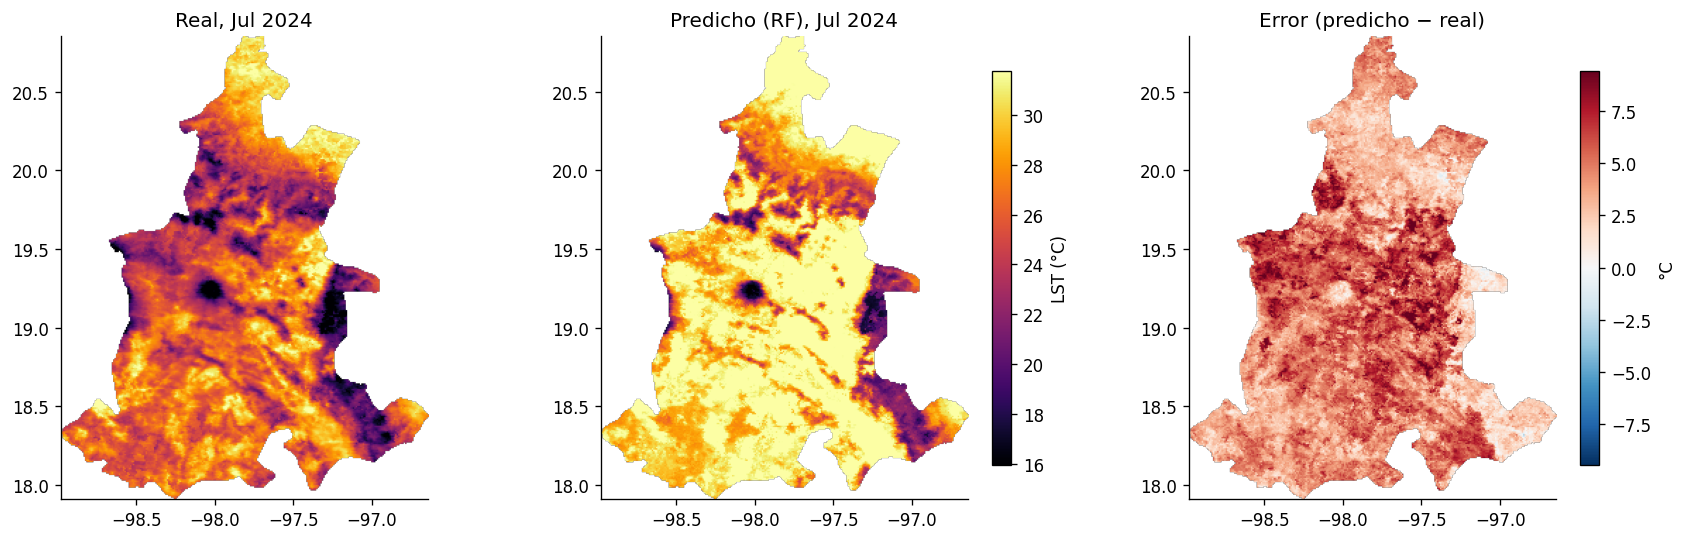

In [9]:
mejor = metricas_2024.loc[metricas_2024["metodo"].isin(MODELOS), "metodo"].iloc[0]
mes_ej = int(por_mes.assign(m=range(1, 13)).loc[por_mes[mejor].idxmax(), "m"])   # el mes más difícil
real = ev.a_mapa(prueba, "LST", mes_ej, FORMA)
pred = ev.a_mapa(prueba, f"pred_{mejor}", mes_ej, FORMA)
lim = np.nanpercentile(np.abs(pred - real), 99)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), layout="constrained")
vmin, vmax = np.nanpercentile(real, [1, 99])
for ax, img, titulo in ((axes[0], real, "Real"), (axes[1], pred, f"Predicho ({mejor})")):
    im = ax.imshow(img, cmap="inferno", vmin=vmin, vmax=vmax, extent=EXTENSION)
    ax.set_title(f"{titulo}, {ev.NOMBRES_MES[mes_ej - 1]} 2024"); ax.grid(False)
fig.colorbar(im, ax=axes[1], label="LST (°C)", shrink=0.85)
im = axes[2].imshow(pred - real, cmap="RdBu_r", vmin=-lim, vmax=lim, extent=EXTENSION)
axes[2].set_title("Error (predicho − real)"); axes[2].grid(False)
fig.colorbar(im, ax=axes[2], label="°C", shrink=0.85)
fig.savefig("figuras/mapas_2024_real_predicho_error.png", dpi=200); plt.show()

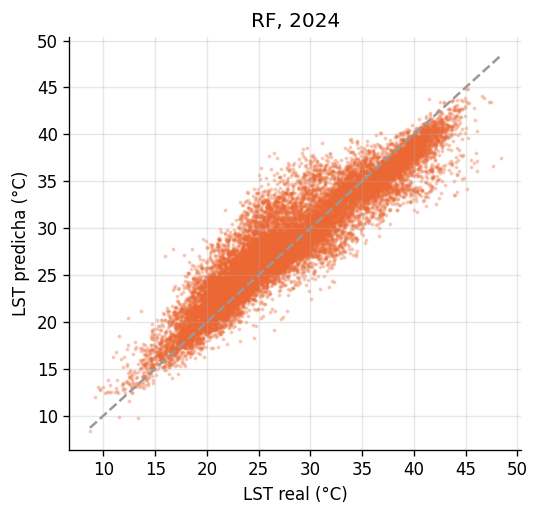

In [10]:
fig, ax = plt.subplots(figsize=(4.6, 4.4))
muestra = prueba.sample(20000, random_state=1)
ax.scatter(muestra["LST"], muestra[f"pred_{mejor}"], s=2, alpha=0.25, color=COLORES[mejor])
lims = [muestra["LST"].min(), muestra["LST"].max()]
ax.plot(lims, lims, ls="--", color="#999999")
ax.set_xlabel("LST real (°C)"); ax.set_ylabel("LST predicha (°C)"); ax.set_title(f"{mejor}, 2024")
fig.tight_layout(); fig.savefig("figuras/real_vs_predicho_2024.png", dpi=200); plt.show()

## 5. Predicción paralela de los mapas de 2024

Predecir los ~490 mil pixel-mes de 2024 es costoso para **KNN con todos los datos** (buscar 10 vecinos entre 3.1 millones de registros) y para **SVR** (evaluar el kernel contra todos los vectores de soporte). Los pixeles se parten en bloques y cada proceso predice los suyos.
- **KNN_todos:** los 3.1 M registros y los pixeles a predecir están en memoria compartida; cada proceso construye su índice sobre ellos sin copiarlos. El tiempo incluye construir el índice.
- **SVR:** el modelo entrenado se envía una sola vez a cada proceso.

Se mide con 1, 2, …, 8 procesos y se verifica que el resultado sea igual al secuencial.

In [11]:
filas = []
for nombre in ("KNN_todos", "SVR"):
    tiempos_pred = {}
    for p in LISTA_PROCESOS:
        if nombre == "KNN_todos":
            y_p, tiempos_pred[p] = par.predecir_knn_paralelo(X_todo_s, y_todo, X_pru_s, params_knn, procesos=p)
        else:
            y_p, tiempos_pred[p] = par.predecir_paralelo(entrenados[nombre], X_pru, procesos=p)
        if p == 1:
            y_1 = y_p
        print(f"{nombre} {p:>2} procesos: {tiempos_pred[p]:7.2f} s  | dif. máx. con secuencial = {np.abs(y_p - y_1).max():.1e}")
    filas.append(par.metricas_paralelas(tiempos_pred).assign(modelo=nombre))
prediccion_paralela = pd.concat(filas, ignore_index=True)
prediccion_paralela.to_csv("resultados/prediccion_paralela.csv", index=False)
prediccion_paralela.round(3)

KNN_todos  1 procesos:  483.95 s  | dif. máx. con secuencial = 0.0e+00
KNN_todos  2 procesos:  358.39 s  | dif. máx. con secuencial = 0.0e+00
KNN_todos  3 procesos:  216.66 s  | dif. máx. con secuencial = 0.0e+00
KNN_todos  4 procesos:  193.56 s  | dif. máx. con secuencial = 0.0e+00
KNN_todos  5 procesos:  174.83 s  | dif. máx. con secuencial = 0.0e+00
KNN_todos  6 procesos:  162.71 s  | dif. máx. con secuencial = 0.0e+00
KNN_todos  7 procesos:  157.02 s  | dif. máx. con secuencial = 0.0e+00
KNN_todos  8 procesos:  158.49 s  | dif. máx. con secuencial = 0.0e+00
SVR  1 procesos: 1115.63 s  | dif. máx. con secuencial = 0.0e+00
SVR  2 procesos:  636.55 s  | dif. máx. con secuencial = 0.0e+00
SVR  3 procesos:  495.02 s  | dif. máx. con secuencial = 0.0e+00
SVR  4 procesos:  416.91 s  | dif. máx. con secuencial = 0.0e+00
SVR  5 procesos:  373.37 s  | dif. máx. con secuencial = 0.0e+00
SVR  6 procesos:  344.19 s  | dif. máx. con secuencial = 0.0e+00
SVR  7 procesos:  320.91 s  | dif. máx. co

,procesos,tiempo_s,speedup,eficiencia,karp_flatt,modelo
0,1,483.950,1.000,1.000,NaN,KNN_todos
1,2,358.391,1.350,0.675,0.481,KNN_todos
2,3,216.663,2.234,0.745,0.172,KNN_todos
3,4,193.559,2.500,0.625,0.200,KNN_todos
4,5,174.835,2.768,0.554,0.202,KNN_todos
5,6,162.708,2.974,0.496,0.203,KNN_todos
6,7,157.022,3.082,0.440,0.212,KNN_todos
7,8,158.495,3.053,0.382,0.231,KNN_todos
8,1,1115.627,1.000,1.000,NaN,SVR
9,2,636.555,1.753,0.876,0.141,SVR


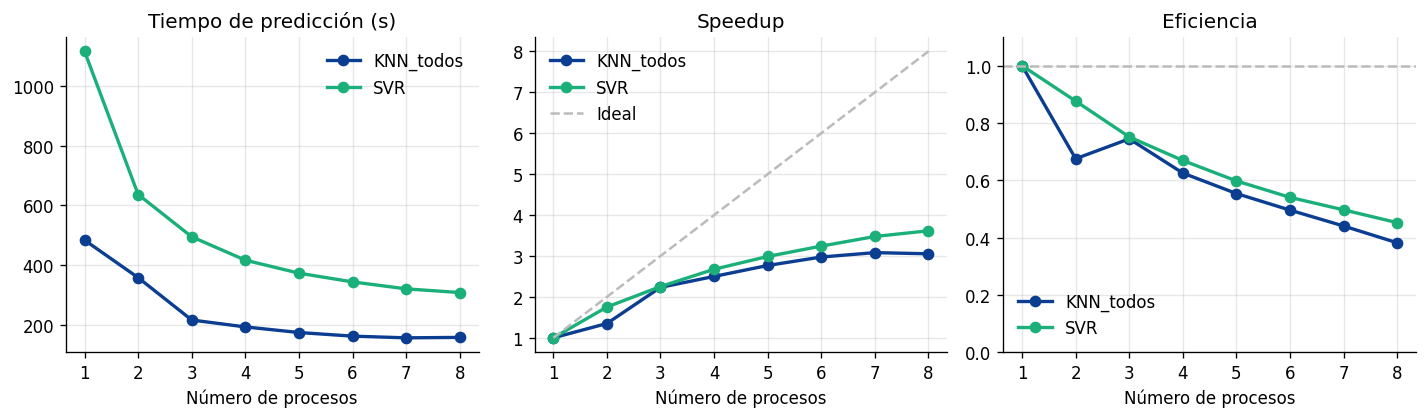

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for nombre, g in prediccion_paralela.groupby("modelo"):
    axes[0].plot(g["procesos"], g["tiempo_s"], marker="o", lw=2, color=COLORES[nombre], label=nombre)
    axes[1].plot(g["procesos"], g["speedup"], marker="o", lw=2, color=COLORES[nombre], label=nombre)
    axes[2].plot(g["procesos"], g["eficiencia"], marker="o", lw=2, color=COLORES[nombre], label=nombre)
axes[1].plot(LISTA_PROCESOS, LISTA_PROCESOS, ls="--", color="#bbbbbb", label="Ideal")
axes[2].axhline(1, ls="--", color="#bbbbbb"); axes[2].set_ylim(0, 1.1)
for ax, t in zip(axes, ("Tiempo de predicción (s)", "Speedup", "Eficiencia")):
    ax.set_title(t); ax.set_xlabel("Número de procesos"); ax.set_xticks(LISTA_PROCESOS); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig("figuras/prediccion_paralela.png", dpi=200); plt.show()

## 6. Resumen

In [13]:
print("Mejor modelo en 2024:", mejor)
display(metricas_2024.round(3))
v2 = tabla_v2.set_index("procesos")
print(f"Construcción de la tabla: v1 secuencial {tiempos_v1[1]:.2f} s -> v2 con {LISTA_PROCESOS[-1]} procesos "
      f"{v2.loc[LISTA_PROCESOS[-1], 'tiempo_s']:.2f} s")
prediccion_paralela.loc[prediccion_paralela["procesos"] == LISTA_PROCESOS[-1]].round(3)

Mejor modelo en 2024: RF


,metodo,RMSE,MAE,R2
0,RF,2.511,1.899,0.860
1,SVR,2.560,1.980,0.855
2,KNN,2.639,2.033,0.845
3,KNN_todos,2.768,2.093,0.830
4,Climatologia,2.887,2.297,0.815
5,Persistencia_t12,3.417,2.589,0.741
6,Persistencia_t1,3.929,2.990,0.658


Construcción de la tabla: v1 secuencial 12.57 s -> v2 con 8 procesos 5.02 s


,procesos,tiempo_s,speedup,eficiencia,karp_flatt,modelo
7,8,158.495,3.053,0.382,0.231,KNN_todos
15,8,308.543,3.616,0.452,0.173,SVR
